Ausgewählter Gitterplatz: 3
spin konfiguration original: [-1  1 -1 -1 -1 -1 -1  1]
Neue Konfiguration         : [-1  1 -1  1 -1 -1 -1  1]
spin konfiguration aktuell: [-1  1 -1 -1 -1 -1 -1  1]
Neue Konfiguration nicht angenommen (a = 0.0183, y = 0.1512)
delta_H =  4
Akzeptanzwahrscheinlichkeit: 0.01831563888873418
Mittlere Magnetisierung: 0.102425
Statistischer Fehler: 0.047950395967967234


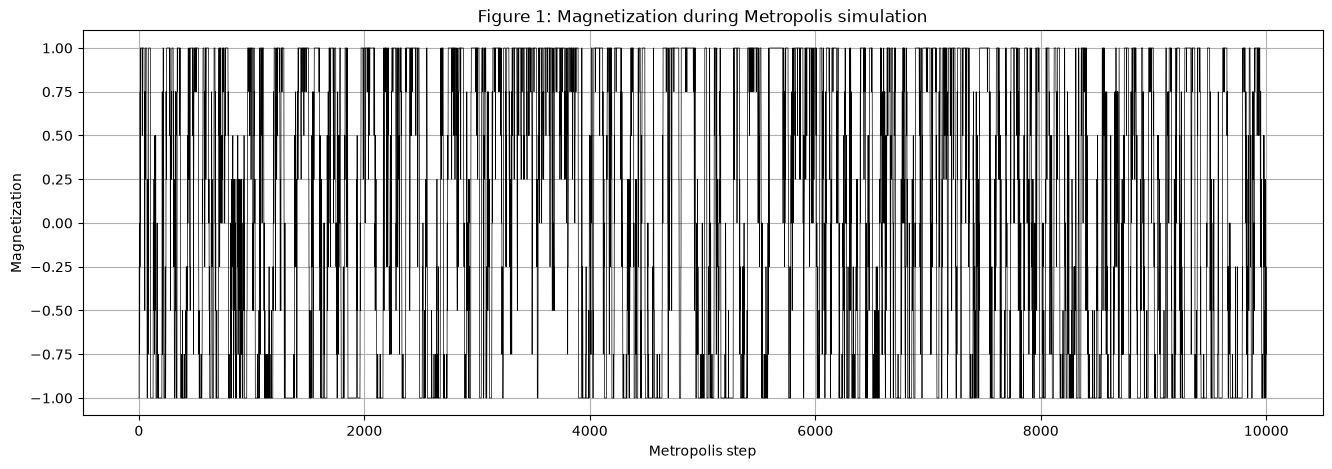

In [2]:
import numpy as np

#Step 1: create a random spin konfiguration

#Anzahl der Spins
N_sweeps = 10000  #Anzahl der Schritte im Metropolis Hastings Algorithmus
N = 8
N_steps = N_sweeps * N
J = 1
T = 1
h = 0
rng = np.random.default_rng(760214)    #erstellt zufallszahlen Generator
spins = rng.choice([-1, 1], size=N)  # Erstellt den array ,,spins". Der array hat die größe 8, also geht von 0 bis 7 und jeder Wert in dem array hat zufällig den Wert - oder + 1


#Step 2: Implement Delta_H

def delta_H(spins, i, h):
    left = spins[(i - 1) % N]   #takes periodic boundary conditions into account
    right = spins[(i + 1) % N]   #takes periodic boundary conditions into account

    delta_H = 2 * spins[i] * (J * (left + right) + h)

    return delta_H

# Step 3: Define proposal funktion

def proposal():
    i = rng.integers(N)   #erzeugt zufällige Zahl i zwischen 0 und 7
    return i      #speichert ausgewählten platz i
i = proposal()
dH = delta_H(spins,i,h)


#Step 4: Spin flip erzeugen
def flip_spin(spins, i):
    new_spins = spins.copy()
    new_spins[i] *= -1
    return new_spins

spins_new = flip_spin(spins, i)
print("Ausgewählter Gitterplatz:", i)
print("spin konfiguration original:", spins)
print("Neue Konfiguration         :", spins_new)

#Step 5: acceptance Propability
def acceptance_probability(dH):
    p = np.exp(-dH/T)
    return min(1, p)

a = acceptance_probability(dH)

y = rng.random()   #erzeugt eine zufallszahl y zwischen 0 und 1
if y <= a:                  #wenn y kleiner als a ist, wird die neue spin konfiguration angenommen und spins wird zu spins_new
    spins = spins_new


print("spin konfiguration aktuell:", spins)
if y <= a:
    print(f"Neue Konfiguration angenommen (a = {a:.4f}, y = {y:.4f})")
else:
    print(f"Neue Konfiguration nicht angenommen (a = {a:.4f}, y = {y:.4f})")
print("delta_H = ", dH)
print("Akzeptanzwahrscheinlichkeit:", a)


#Step 6: Magnetisierung der Spinkonfiguration berechnen
def magnetization(spins):
    m = np.sum(spins) / N
    return m
magnetizations = []


# Thermalization

N_thermal_sweeps = 1000

for sweep in range(N_thermal_sweeps):
    for step in range(N):
        i = proposal()
        dH = delta_H(spins, i, h)
        spins_new = flip_spin(spins, i)

        a = acceptance_probability(dH)
        y = rng.random()

        if y <= a:
            spins = spins_new

#Messschleife

for sweep in range(N_sweeps):
    for step in range(N):
        i = proposal()
        dH = delta_H(spins, i, h)
        spins_new = flip_spin(spins, i)

        a = acceptance_probability(dH)
        y = rng.random()

        if y <= a:
            spins = spins_new

    m = magnetization(spins)
    magnetizations.append(float(m))

#print("Magentisierungen:", magnetizations)


#Step 7: Mittlere Magentisierung berechnen:
mean_magnetization = np.mean(magnetizations)
print("Mittlere Magnetisierung:", mean_magnetization)

#Step 8: Fehlerrechnung:
def calculate_error(magnetizations, block_size=100):

    N_blocks = len(magnetizations) // block_size

    blocks = np.array(magnetizations[:N_blocks * block_size])
    blocks = blocks.reshape(N_blocks, block_size)

    block_means = np.mean(blocks, axis=1)

    error = np.std(block_means, ddof=1) / np.sqrt(N_blocks)

    return error
error = calculate_error(magnetizations)

print("Statistischer Fehler:", error)


#Plot erstellen
import matplotlib.pyplot as plt
plt.figure(figsize=(16, 5))
plt.plot(
    range(1, N_sweeps + 1),
    magnetizations,
    color='black',
    linewidth=0.5
)

plt.xlabel("Metropolis step")
plt.ylabel("Magnetization")
plt.title("Figure 1: Magnetization during Metropolis simulation")
plt.grid()

plt.show()

Exercise 3:

Abhängigkeit von der Magnetfeldstärke

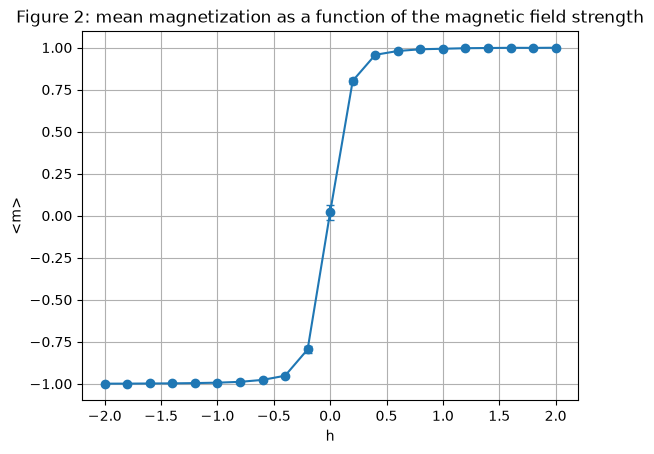

In [3]:
h_values = np.linspace(-2, 2, 21)

mean_m_h = []
error_m_h = []


for h in h_values:

    spins = rng.choice([-1, 1], size=N)

    # Thermalisierung
    for sweep in range(N_thermal_sweeps):
        for step in range(N):
            i = rng.integers(N)
            dH = delta_H(spins, i, h)
            a = min(1, np.exp(-dH/T))

            if rng.random() <= a:
                spins[i] *= -1

    # Messphase
    magnetizations_h = []

    for sweep in range(N_sweeps):
        for step in range(N):
            i = rng.integers(N)
            dH = delta_H(spins, i, h)
            a = min(1, np.exp(-dH/T))

            if rng.random() <= a:
                spins[i] *= -1

        magnetizations_h.append(np.sum(spins)/N)

    mean_m_h.append(np.mean(magnetizations_h))

    # Fehlerrechnung
    error_m_h.append(calculate_error(magnetizations_h))


# Plot
plt.errorbar(
    h_values,
    mean_m_h,
    yerr=error_m_h,
    fmt="o-",
    capsize=3
)
plt.title("Figure 2: mean magnetization as a function of the magnetic field strength")
plt.xlabel("h")
plt.ylabel("<m>")
plt.grid()
plt.show()

Änderung der mittleren Magnetisierung in Abhängigkeit der Spins im System

Mittlere Magnetisierung für verschiedene N:
N =   2: <m> = -0.04320 ± 0.06275
N =   7: <m> = 0.01511 ± 0.04897
N =  12: <m> = 0.01927 ± 0.03892
N =  17: <m> = -0.01280 ± 0.03541
N =  22: <m> = 0.04404 ± 0.03046
N =  27: <m> = 0.01669 ± 0.02596
N =  32: <m> = 0.02392 ± 0.02107
N =  38: <m> = 0.03375 ± 0.02229
N =  43: <m> = -0.01107 ± 0.02023
N =  48: <m> = -0.00224 ± 0.02070
N =  53: <m> = -0.04161 ± 0.02056
N =  58: <m> = 0.00212 ± 0.02023
N =  63: <m> = 0.00413 ± 0.01855
N =  69: <m> = 0.04305 ± 0.01504
N =  74: <m> = 0.00684 ± 0.01651
N =  79: <m> = -0.02648 ± 0.01554
N =  84: <m> = 0.00255 ± 0.01404
N =  89: <m> = 0.01798 ± 0.01472
N =  94: <m> = -0.04620 ± 0.01455
N = 100: <m> = 0.00394 ± 0.01423


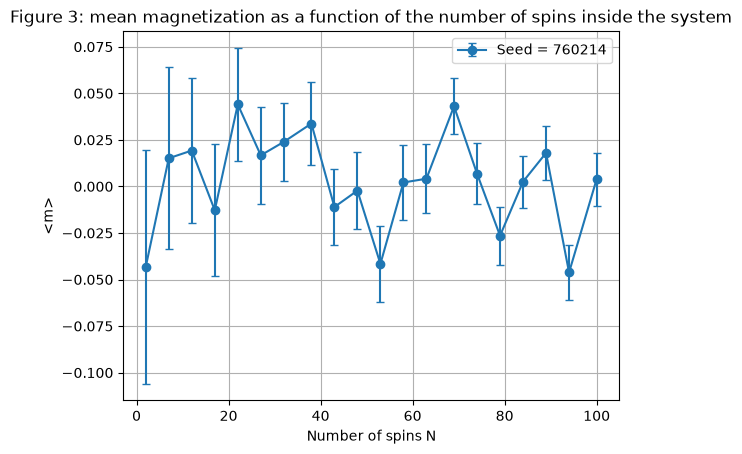

In [4]:
spin_counts = np.linspace(2, 100, 20, dtype=int)
h = 0

mean_m_N = []
error_m_N = []


# Simulation für verschiedene Spinanzahlen
for N in spin_counts:

    spins = rng.choice([-1, 1], size=N)

    # Thermalisierung
    for sweep in range(N_thermal_sweeps):
        for step in range(N):
            i = rng.integers(N)
            dH = delta_H(spins, i, h)
            a = min(1, np.exp(-dH/T))

            if rng.random() <= a:
                spins[i] *= -1

    # Messphase
    magnetizations_N = []

    for sweep in range(N_sweeps):
        for step in range(N):
            i = rng.integers(N)
            dH = delta_H(spins, i, h)
            a = min(1, np.exp(-dH/T))

            if rng.random() <= a:
                spins[i] *= -1

        magnetizations_N.append(np.sum(spins)/N)

    # Mittelwert
    mean_m_N.append(np.mean(magnetizations_N))

    # Fehlerrechnung
    error_m_N.append(calculate_error(magnetizations_N))


print("Mittlere Magnetisierung für verschiedene N:")

for N, m, error in zip(spin_counts, mean_m_N, error_m_N):
    print(f"N = {N:3d}: <m> = {m:.5f} ± {error:.5f}")

# Plot
plt.errorbar(
    spin_counts,
    mean_m_N,
    yerr=error_m_N,
    fmt="o-",
    capsize=3,
    label="Seed = 760214"
)
plt.title("Figure 3: mean magnetization as a function of the number of spins inside the system")
plt.xlabel("Number of spins N")
plt.ylabel("<m>")
plt.legend()
plt.grid()
plt.show()

Exercise 4: Comparison with the analytical solution

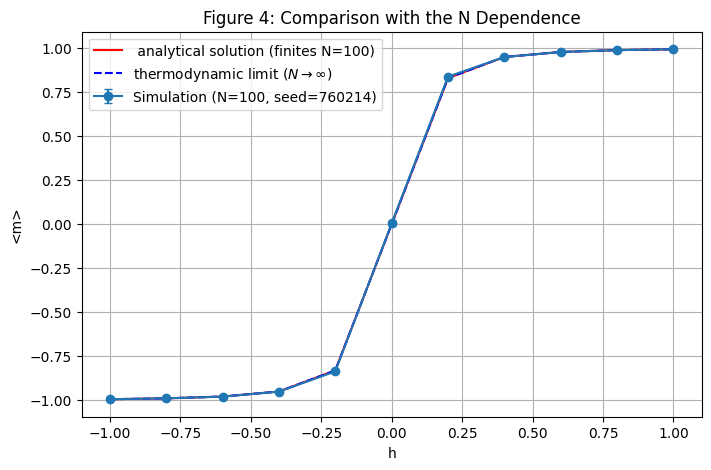

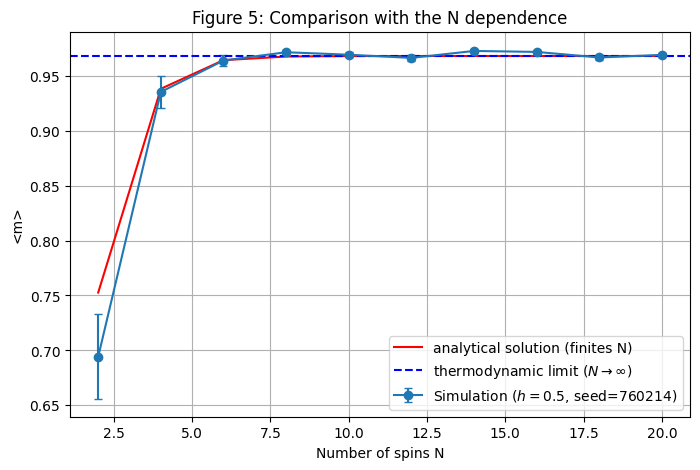

In [263]:
h_values = np.linspace(-1, 1, 11)
mean_m_h = []
error_m_h = []


# Berechnung von Z: 
def partition_function(N, h, J, T):
    cosh_h = np.cosh(h / T)
    sinh_h = np.sinh(h / T)
    root = np.sqrt(sinh_h**2 + np.exp(-4 * J / T))
    lam_plus = np.exp(J / T) * (cosh_h + root)
    lam_minus = np.exp(J / T) * (cosh_h - root)
    return lam_plus**N + lam_minus**N

#mittlere magnetisierung analytisch berechnen
def exact_finite_N(N, h, J, T):
    eps = 1e-5
    Z_p = partition_function(N, h + eps, J, T)
    Z_m = partition_function(N, h - eps, J, T)
    dZ = (Z_p - Z_m) / (2 * eps)
    Z = partition_function(N, h, J, T)
    return (T / N) * (dZ / Z)

#mittlere magnetisierung analytisch berechnen im Grenzfall N -> unendlich
def exact_infinite(h, J, T):
    sinh_h = np.sinh(h / T)
    return sinh_h / np.sqrt(sinh_h**2 + np.exp(-4 * J / T))


for h_val in h_values:
    spins = rng.choice([-1, 1], size=N)

    # Thermalisierung
    for sweep in range(N_thermal_sweeps):
        for step in range(N):
            i = rng.integers(N)
            left = spins[(i - 1) % N]
            right = spins[(i + 1) % N]
            dH = 2 * spins[i] * (J * (left + right) + h_val)
            a = min(1, np.exp(-dH / T))
            if rng.random() <= a:
                spins[i] *= -1

    # Messphase
    magnetizations_h = []
    for sweep in range(N_sweeps):
        for step in range(N):
            i = rng.integers(N)
            left = spins[(i - 1) % N]
            right = spins[(i + 1) % N]
            dH = 2 * spins[i] * (J * (left + right) + h_val)
            a = min(1, np.exp(-dH / T))
            if rng.random() <= a:
                spins[i] *= -1
        magnetizations_h.append(np.sum(spins) / N)

    mean_m_h.append(np.mean(magnetizations_h))
    error_m_h.append(calculate_error(magnetizations_h))


exact_m_h = [exact_finite_N(N, h_val, J, T) for h_val in h_values]
inf_m_h = [exact_infinite(h_val, J, T) for h_val in h_values]

plt.figure(figsize=(8, 5))
plt.errorbar(h_values, mean_m_h, yerr=error_m_h, fmt="o-", capsize=3, label=f"Simulation (N={N}, seed={seed})")
plt.plot(h_values, exact_m_h, "r-", label=f" analytical solution (finites N={N})")
plt.plot(h_values, inf_m_h, "b--", label="thermodynamic limit ($N \\to \\infty$)")
plt.xlabel("h")
plt.ylabel("<m>")
plt.title("Figure 4: Comparison with the N Dependence")
plt.legend()
plt.grid()
plt.show()



#Vergleich der Abhängigkeit von N mit der analytischen Lösung (für festes h = 0.5, N bis max ~20) ---
h_fixed = 0.5                      # Ein externes Feld ungleich 0 (bei h=0 ist m=0)
spin_counts = np.arange(2, 21, 2)  # N von 2 bis 20 wie in Aufgabe 4 gefordert

mean_m_N = []
error_m_N = []

for N_val in spin_counts:
    spins = rng.choice([-1, 1], size=N_val)

    # Thermalisierung
    for sweep in range(N_thermal_sweeps):
        for step in range(N_val):
            i = rng.integers(N_val)
            left = spins[(i - 1) % N_val]
            right = spins[(i + 1) % N_val]
            dH = 2 * spins[i] * (J * (left + right) + h_fixed)
            a = min(1, np.exp(-dH / T))
            if rng.random() <= a:
                spins[i] *= -1

    # Messphase
    magnetizations_N = []
    for sweep in range(N_sweeps):
        for step in range(N_val):
            i = rng.integers(N_val)
            left = spins[(i - 1) % N_val]
            right = spins[(i + 1) % N_val]
            dH = 2 * spins[i] * (J * (left + right) + h_fixed)
            a = min(1, np.exp(-dH / T))
            if rng.random() <= a:
                spins[i] *= -1
        magnetizations_N.append(np.sum(spins) / N_val)

    mean_m_N.append(np.mean(magnetizations_N))
    error_m_N.append(calculate_error(magnetizations_N))

# Exakte Werte und thermodynamischen Limes für N berechnen
exact_m_N = [exact_finite_N(N_val, h_fixed, J, T) for N_val in spin_counts]
inf_val = exact_infinite(h_fixed, J, T)

# Plot für N-Abhängigkeit
plt.figure(figsize=(8, 5))
plt.errorbar(spin_counts, mean_m_N, yerr=error_m_N, fmt="o-", capsize=3, label=f"Simulation ($h={h_fixed}$, seed={seed})")
plt.plot(spin_counts, exact_m_N, "r-", label="analytical solution (finites N)")
plt.axhline(inf_val, color="b", linestyle="--", label="thermodynamic limit ($N \\to \\infty$)")
plt.xlabel("Number of spins N")
plt.ylabel("<m>")
plt.title("Figure 5: Comparison with the N dependence")
plt.legend()
plt.grid()
plt.show()